# Final Data Science Capstone Project
## Breast Cancer Diagnosis Classification and Model Evaluation

**Project 6 | Comprehensive Portfolio Capstone**

### Executive overview
This capstone demonstrates an end-to-end data science workflow using the Breast Cancer Wisconsin (Diagnostic) dataset available through Scikit-learn. The research problem is to investigate whether measurements computed from digitized images of breast mass samples can distinguish benign from malignant cases in this benchmark dataset.

**Important:** This is an educational machine-learning exercise, not a medical device, diagnostic recommendation, or clinically validated model.

## 1. Capstone problem definition

### Problem statement
Can a supervised classification model use the dataset's numeric measurements to distinguish the two diagnosis classes, and how reliably does it perform on held-out observations?

### Objectives
- Load and profile a documented, publicly available benchmark dataset.
- Inspect data quality and explore feature and target distributions.
- Prepare features and target for model training.
- Train and compare Logistic Regression and Random Forest classifiers.
- Evaluate generalization using a stratified hold-out set and stratified cross-validation.
- Examine errors, limitations, and feature-level signals.
- Translate the evidence into cautious, practical recommendations.

### Scope and expected outcomes
The scope is limited to a reproducible binary classification experiment on the supplied benchmark dataset. Expected outputs include descriptive summaries, visualizations, model metrics, confusion matrices, ROC curves, cross-validation results, error analysis, and recommendations.

### Intended audience
Data science learners, project reviewers, and stakeholders interested in understanding a complete model-development workflow.

## 2. Data source and collection

The dataset is loaded using `sklearn.datasets.load_breast_cancer`, so no separate download is required. It contains 569 observations, 30 numeric features, and a binary target. Scikit-learn describes the target labels as malignant and benign; the target encoding is checked in the code below rather than assumed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()
target_names = dataset.target_names

df = X.copy()
df["target"] = y
df["diagnosis"] = y.map({i: name for i, name in enumerate(target_names)})

print("Dataset shape:", df.shape)
print("Feature count:", X.shape[1])
print("Target mapping:", {i: name for i, name in enumerate(target_names)})
display(df.head())

Dataset shape: (569, 32)
Feature count: 30
Target mapping: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


## 3. Data preparation and quality assessment

The dataset is already numeric and packaged with Scikit-learn. The following checks review missing values, duplicate rows, data types, summary statistics, and class balance. A train/test split is performed before model fitting. Scaling is placed inside the Logistic Regression pipeline to avoid fitting the scaler on test data.

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
display(X.dtypes.value_counts().rename("column_count").to_frame())
display(X.describe().T.head(10))
class_counts = y.map({i: name for i, name in enumerate(target_names)}).value_counts()
display(class_counts.to_frame("observations"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Missing values: 0
Duplicate feature rows: 0


,column_count
float64,30


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


,observations
target,
benign,357
malignant,212


Training rows: 455 | Test rows: 114


## 4. Exploratory data analysis

Explore the class distribution, selected feature distributions, and correlations among a small set of representative features. EDA is used to understand the data, not to select a model based on the test set.

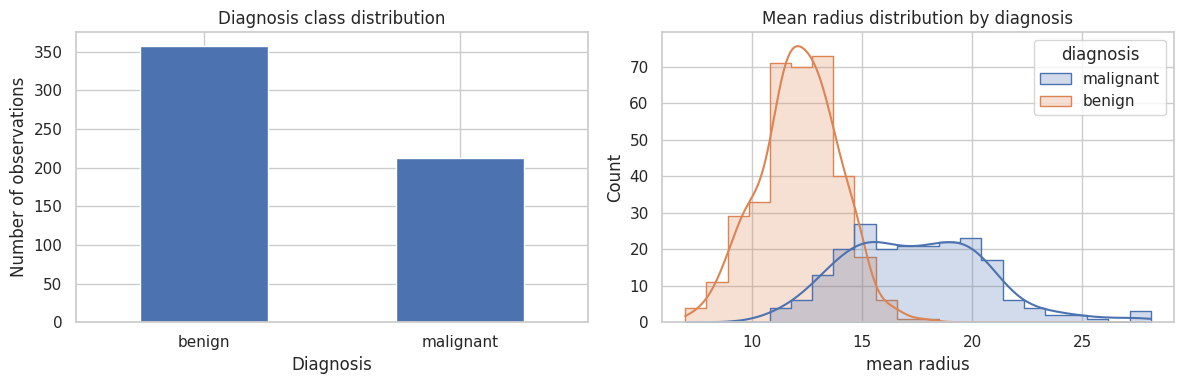

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind="bar", ax=axes[0], title="Diagnosis class distribution")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=0)

sns.histplot(data=df, x="mean radius", hue="diagnosis", kde=True, element="step", ax=axes[1])
axes[1].set_title("Mean radius distribution by diagnosis")
plt.tight_layout()
plt.show()

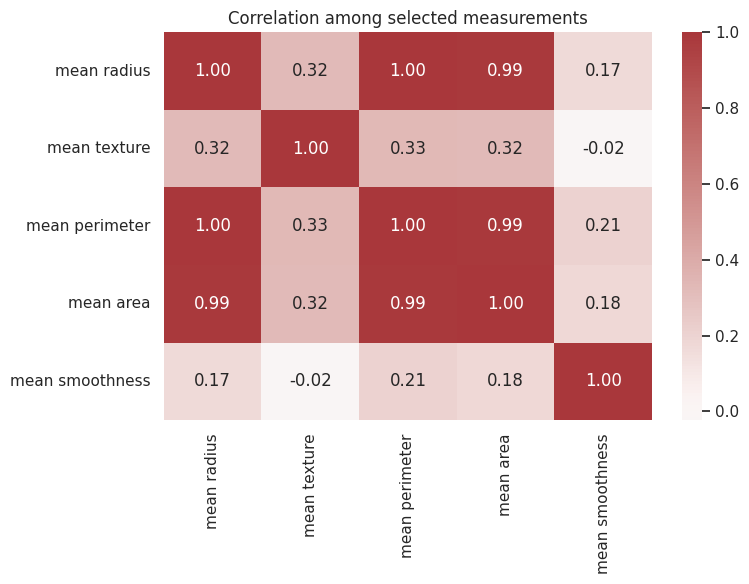

In [5]:
selected = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[selected].corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation among selected measurements")
plt.tight_layout()
plt.show()

## 5. Modeling approach

Two supervised classifiers are compared:
- **Logistic Regression:** a linear baseline. Standardization is included in a Pipeline.
- **Random Forest:** a tree-ensemble model that can represent nonlinear relationships.

The same stratified train/test split is used for both. Evaluation includes accuracy, precision, recall, F1-score, and ROC-AUC. For a screening-oriented research framing, recall for the malignant class is particularly important to inspect; however, no single metric establishes clinical suitability.

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, random_state=RANDOM_STATE,
        class_weight="balanced"
    )
}

results = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).set_index("model")
display(results_df.round(4))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
Random Forest,0.9474,0.9583,0.9583,0.9583,0.9931


## 6. Model evaluation and error analysis

Review confusion matrices and ROC curves. The positive class encoding is confirmed by the dataset metadata: Scikit-learn's target names are ordered as `malignant`, `benign`, with integer labels 0 and 1. Therefore, default positive-class metrics above refer to class 1 (benign). To avoid misinterpretation, the classification report and malignant-class recall are also calculated explicitly below.

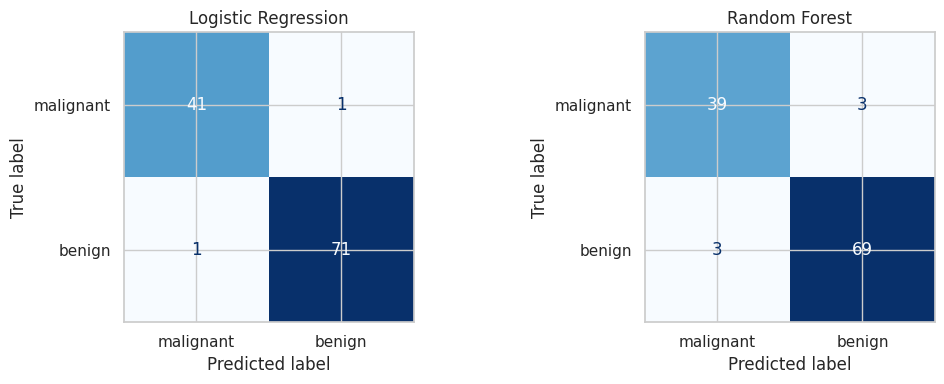

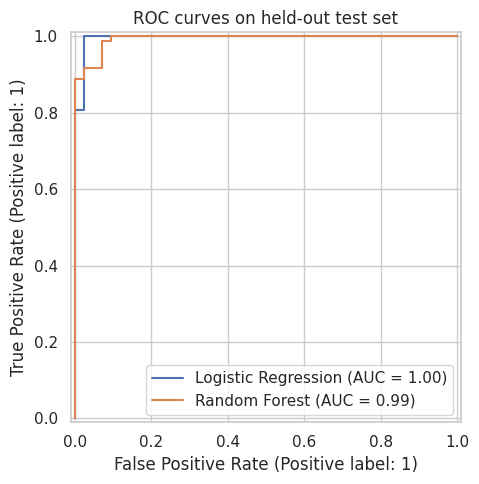

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=target_names, cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.set_title("ROC curves on held-out test set")
plt.tight_layout()
plt.show()

In [8]:
for name, model in fitted.items():
    pred = model.predict(X_test)
    print("\\n", name)
    print(classification_report(y_test, pred, target_names=target_names, digits=4))
    # Explicitly report malignant recall (label 0)
    malignant_recall = recall_score(y_test, pred, pos_label=0)
    print(f"Malignant-class recall: {malignant_recall:.4f}")

\n Logistic Regression
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

Malignant-class recall: 0.9762
\n Random Forest
              precision    recall  f1-score   support

   malignant     0.9286    0.9286    0.9286        42
      benign     0.9583    0.9583    0.9583        72

    accuracy                         0.9474       114
   macro avg     0.9435    0.9435    0.9435       114
weighted avg     0.9474    0.9474    0.9474       114

Malignant-class recall: 0.9286


## 7. Cross-validation

Five-fold stratified cross-validation is performed on the training set. This gives a more stable view of model performance across different training/validation partitions. The held-out test set remains separate for final evaluation.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_recall_mean": scores["test_recall"].mean(),
        "cv_f1_mean": scores["test_f1"].mean(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean()
    })
cv_df = pd.DataFrame(cv_rows).set_index("model")
display(cv_df.round(4))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,cv_accuracy_mean,cv_accuracy_std,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean
model,,,,,
Logistic Regression,0.9780,0.0098,0.9860,0.9825,0.9959
Random Forest,0.9582,0.0146,0.9649,0.9665,0.9908


## 8. Feature signal and interpretation

Permutation importance estimates how much a model's score changes when one feature is shuffled. It is calculated on the held-out test set for the selected model. Correlated features can share or obscure importance, so these values should be interpreted as model-specific signals rather than causal explanations.

,mean_permutation_importance
worst smoothness,0.003638
worst concave points,0.003290
area error,0.003257
radius error,0.003158
worst area,0.002943
worst radius,0.002827
worst texture,0.002646
worst perimeter,0.001984
mean concave points,0.001885
worst concavity,0.001786


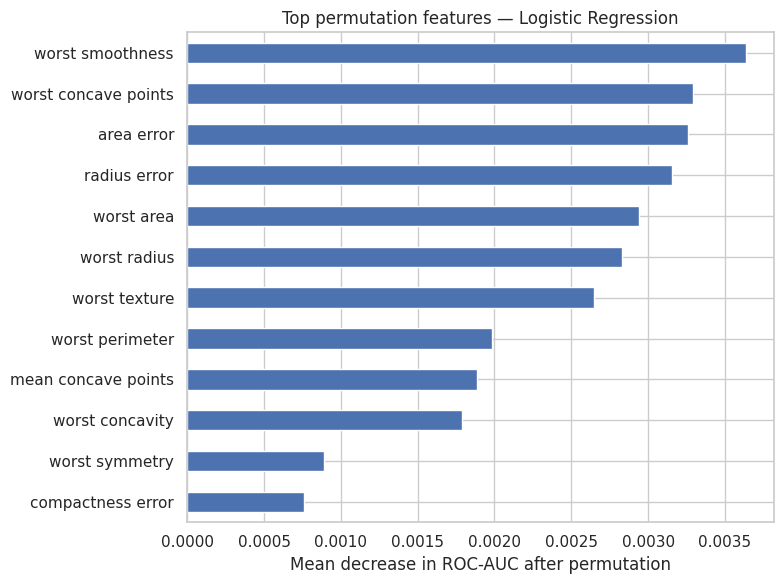

In [10]:
best_model_name = results_df["roc_auc"].idxmax()
best_model = fitted[best_model_name]
perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
    scoring="roc_auc", n_jobs=-1
)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(12)
display(importance.to_frame("mean_permutation_importance"))
importance.sort_values().plot(kind="barh", figsize=(8, 6), title=f"Top permutation features — {best_model_name}")
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.tight_layout()
plt.show()

## 9. Errors, limitations, and improvement opportunities

### Error analysis
False negatives and false positives have different implications in a medical research context. Inspect the confusion matrix and malignant-class recall for each model rather than relying on accuracy alone. Review individual misclassified observations for patterns, but avoid treating model outputs as diagnoses.

### Limitations
- This is a small, historical benchmark dataset and may not represent current clinical populations, imaging systems, or care settings.
- The data are precomputed numeric features, not raw medical images.
- A random train/test split does not establish external validity.
- Correlated predictors can complicate feature interpretation.
- The target distribution and label definitions reflect the benchmark dataset.
- No clinical utility, calibration, fairness, prospective performance, or decision-threshold validation is established.

### Improvement opportunities
- Validate on independent, representative datasets from multiple institutions.
- Assess calibration and threshold trade-offs with domain experts.
- Investigate subgroup performance and potential dataset bias.
- Compare additional models and perform carefully nested hyperparameter tuning.
- Conduct prospective evaluation and formal clinical governance before any real-world use.

## 10. Key insights and recommendations

Use the calculated model comparison, class-specific recall, cross-validation scores, confusion matrices, and feature importance outputs as evidence.

1. Compare models on multiple metrics; do not select solely by accuracy.
2. In a screening-related research setting, pay explicit attention to malignant-class false negatives and recall.
3. Treat feature importance as a hypothesis-generating aid, not a causal explanation.
4. Require external validation, calibration, subgroup assessment, and expert review before considering deployment.
5. Communicate the model's intended scope and limitations alongside every reported metric.

## 11. Executive summary

This capstone evaluates supervised classification on the Scikit-learn Breast Cancer Wisconsin (Diagnostic) benchmark dataset. It uses data inspection, exploratory analysis, preprocessing pipelines, Logistic Regression and Random Forest models, hold-out evaluation, stratified cross-validation, confusion matrices, ROC curves, and permutation importance. The final model comparison is generated by the notebook at runtime. Results should be interpreted as benchmark performance only, not evidence of clinical readiness.

## 12. Conclusion

The capstone demonstrates a complete data science lifecycle: problem definition, data sourcing, preparation, exploratory analysis, model development, evaluation, error review, interpretation, recommendations, and documentation. It emphasizes reproducibility, metric selection aligned to the problem, transparent limitations, and responsible communication.

## 13. References

- Scikit-learn, Breast Cancer Wisconsin (Diagnostic) dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
- Scikit-learn Pipeline: https://scikit-learn.org/stable/modules/compose.html
- Pandas documentation: https://pandas.pydata.org/docs/
- NumPy documentation: https://numpy.org/doc/
- Matplotlib documentation: https://matplotlib.org/stable/
- Seaborn documentation: https://seaborn.pydata.org/